# DSCI 552 | Homework 6
**Haresh Sambandamoorthy**

This notebook presents the analysis and the checked answers from the supplied Homework 6 handout. The corrected logistic model trees are separate from the conventional XGBoost comparison. The complete training scripts are provided alongside this notebook.

## 1(a) APS Failure dataset
We use the provided 60,000-row training set and 16,000-row test set. A positive example is a truck with an APS-related failure.

In [1]:
from pathlib import Path
import json, numpy as np, pandas as pd
from IPython.display import display, Image
ROOT=Path.cwd()
train=pd.read_csv(ROOT/'data/aps_failure_training_set.csv',skiprows=20,na_values='na')
test=pd.read_csv(ROOT/'data/aps_failure_test_set.csv',skiprows=20,na_values='na')
result=json.loads((ROOT/'results/results.json').read_text())
corrected=json.loads((ROOT/'results/model_tree_results.json').read_text())
assert train.shape==(60000,171) and test.shape==(16000,171)
assert (train['class']=='pos').sum()==1000 and (test['class']=='pos').sum()==375
print('Train:',train.shape,'Test:',test.shape)
print('Training labels:',train['class'].value_counts().to_dict())
print('Missing training feature entries:', result['data']['train_missing_cells'])

Train: (60000, 171) Test: (16000, 171)
Training labels: {'neg': 59000, 'pos': 1000}
Missing training feature entries: 850015


## 1(b) Preparing the data
**Missing readings:** Common options are deleting incomplete rows, filling blanks with a mean or median, or using nearby rows. We fill blanks with each feature’s **training median**. The test set uses the same medians, and cross-validation learns medians from each fold’s training rows only.

**CV:** For each feature, compute sample standard deviation divided by mean. All 170 values are saved in `results/all_170_feature_cv.csv`. The thirteen largest are shown below.

In [2]:
cv_features=pd.read_csv(ROOT/'results/all_170_feature_cv.csv')
assert len(cv_features)==170
print('Top 13 features:',', '.join(cv_features.head(13)['feature']))
display(cv_features.head(13).round(4))

Top 13 features: cf_000, co_000, ad_000, cs_009, dh_000, dj_000, ag_000, as_000, ay_009, ak_000, az_009, ch_000, au_000


,feature,mean,sample_sd,cv,missing_pct
0,cf_000,143107.5380,3.504525e+07,244.8875,24.7683
1,co_000,143330.0220,3.504525e+07,244.5074,24.7683
2,ad_000,143438.2960,3.504525e+07,244.3228,24.7683
3,cs_009,770.5097,1.833278e+05,237.9306,1.1150
4,dh_000,4392.6408,5.412441e+05,123.2161,6.6800
5,dj_000,37.2713,4.379166e+03,117.4942,6.6783
6,ag_000,219.1577,2.036364e+04,92.9178,1.1183
7,as_000,125.4079,1.095219e+04,87.3325,1.0483
8,ay_009,1149.6196,9.741156e+04,84.7337,1.1183
9,ak_000,907.6607,7.299859e+04,80.4250,7.3333


### Correlations and the 13 visualization features
The following plots include all 170 features in the correlation chart. The scatter plots show 250 rows per class for visibility, and the box plots use all training rows. These plots are not used to drop features from the model.

02_top_13_cv.png


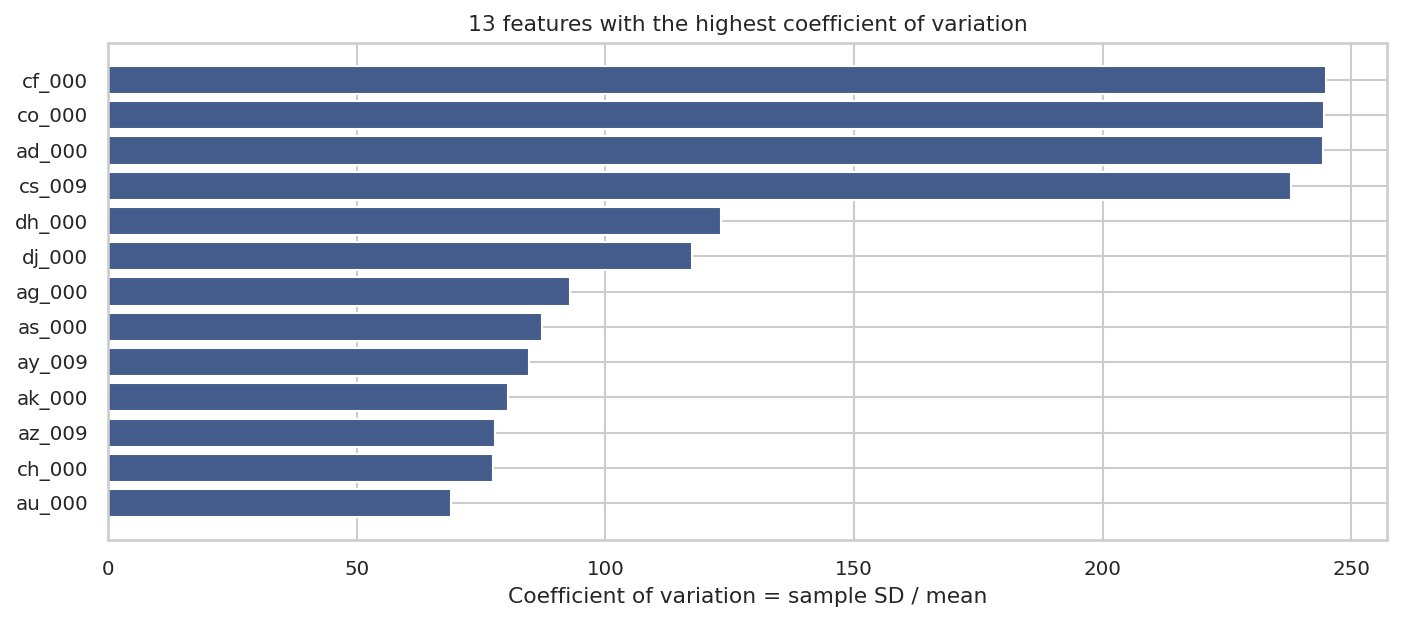

01_correlation_all_features.png


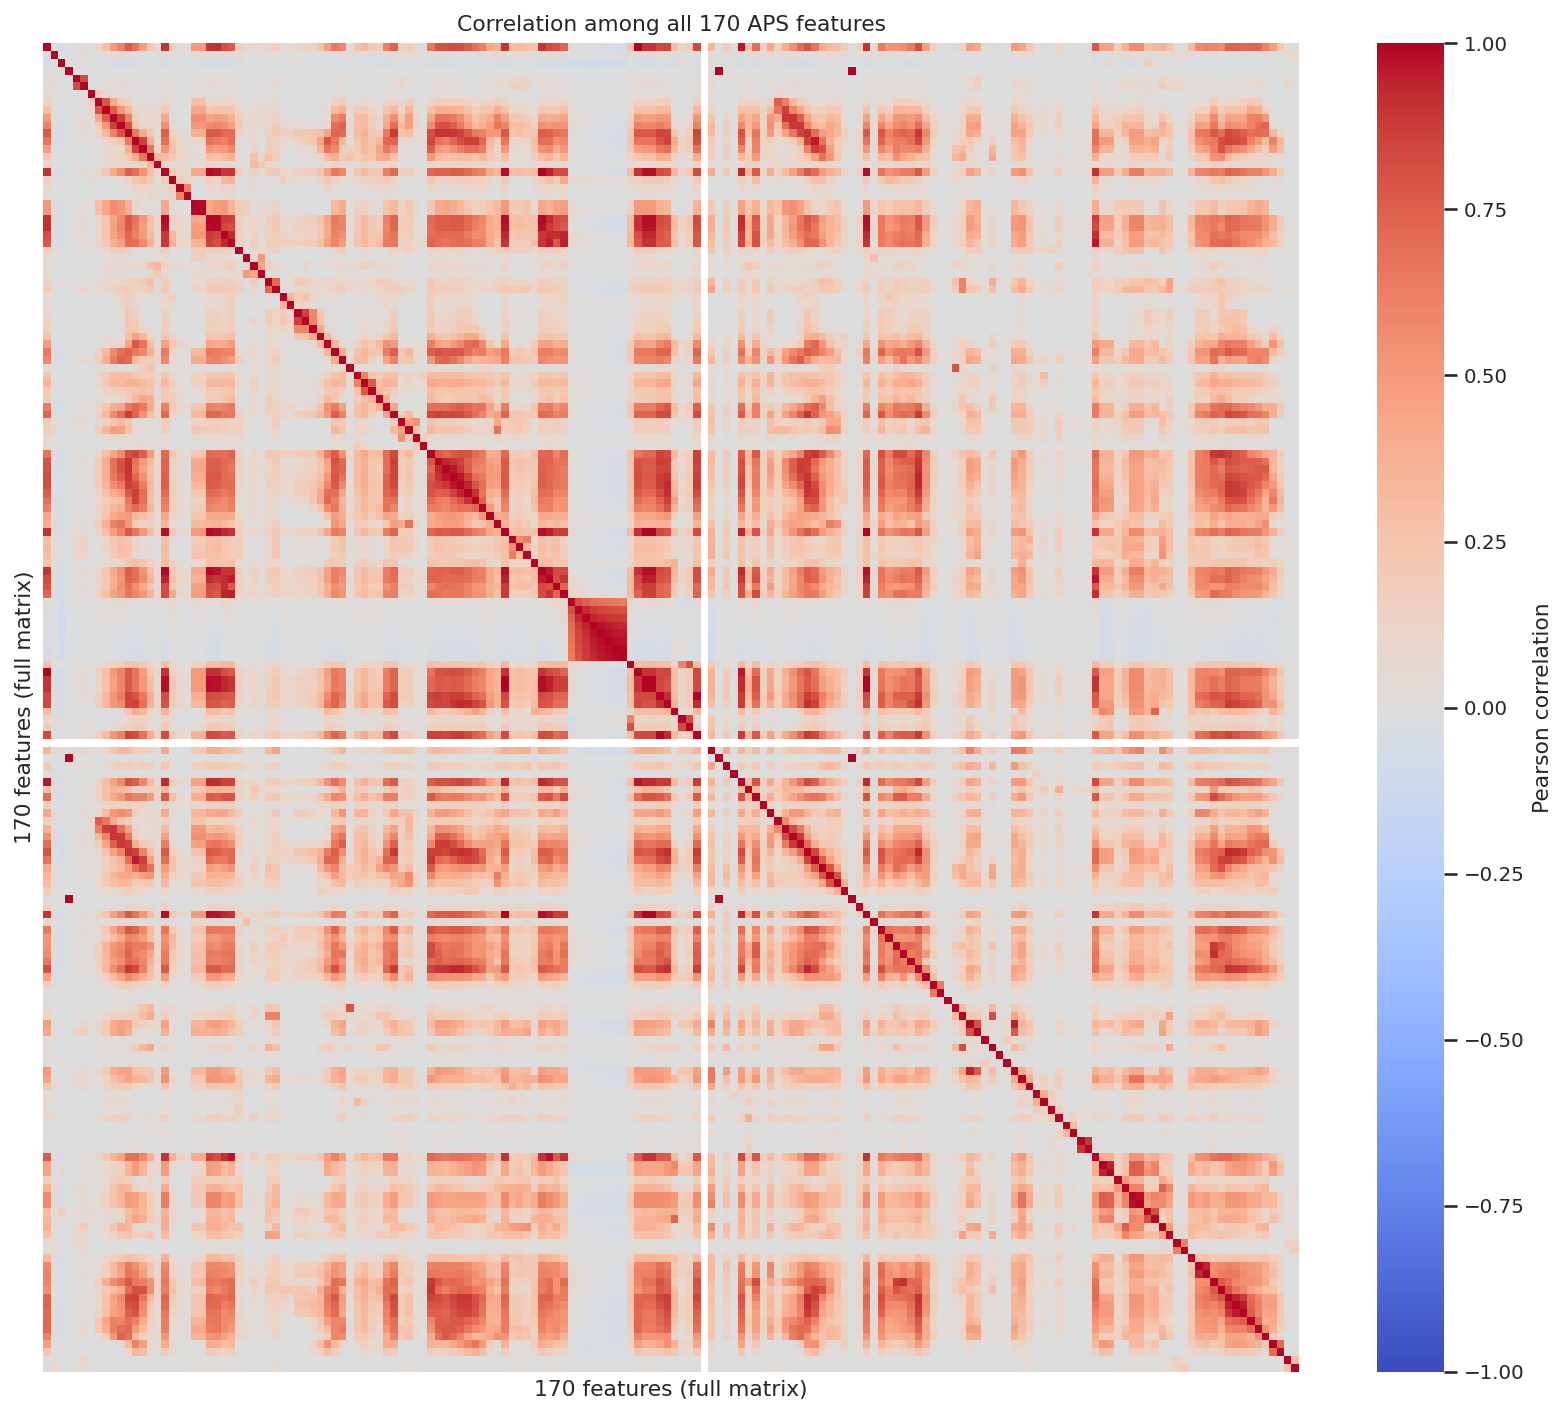

03_scatter_top_13_by_class.png


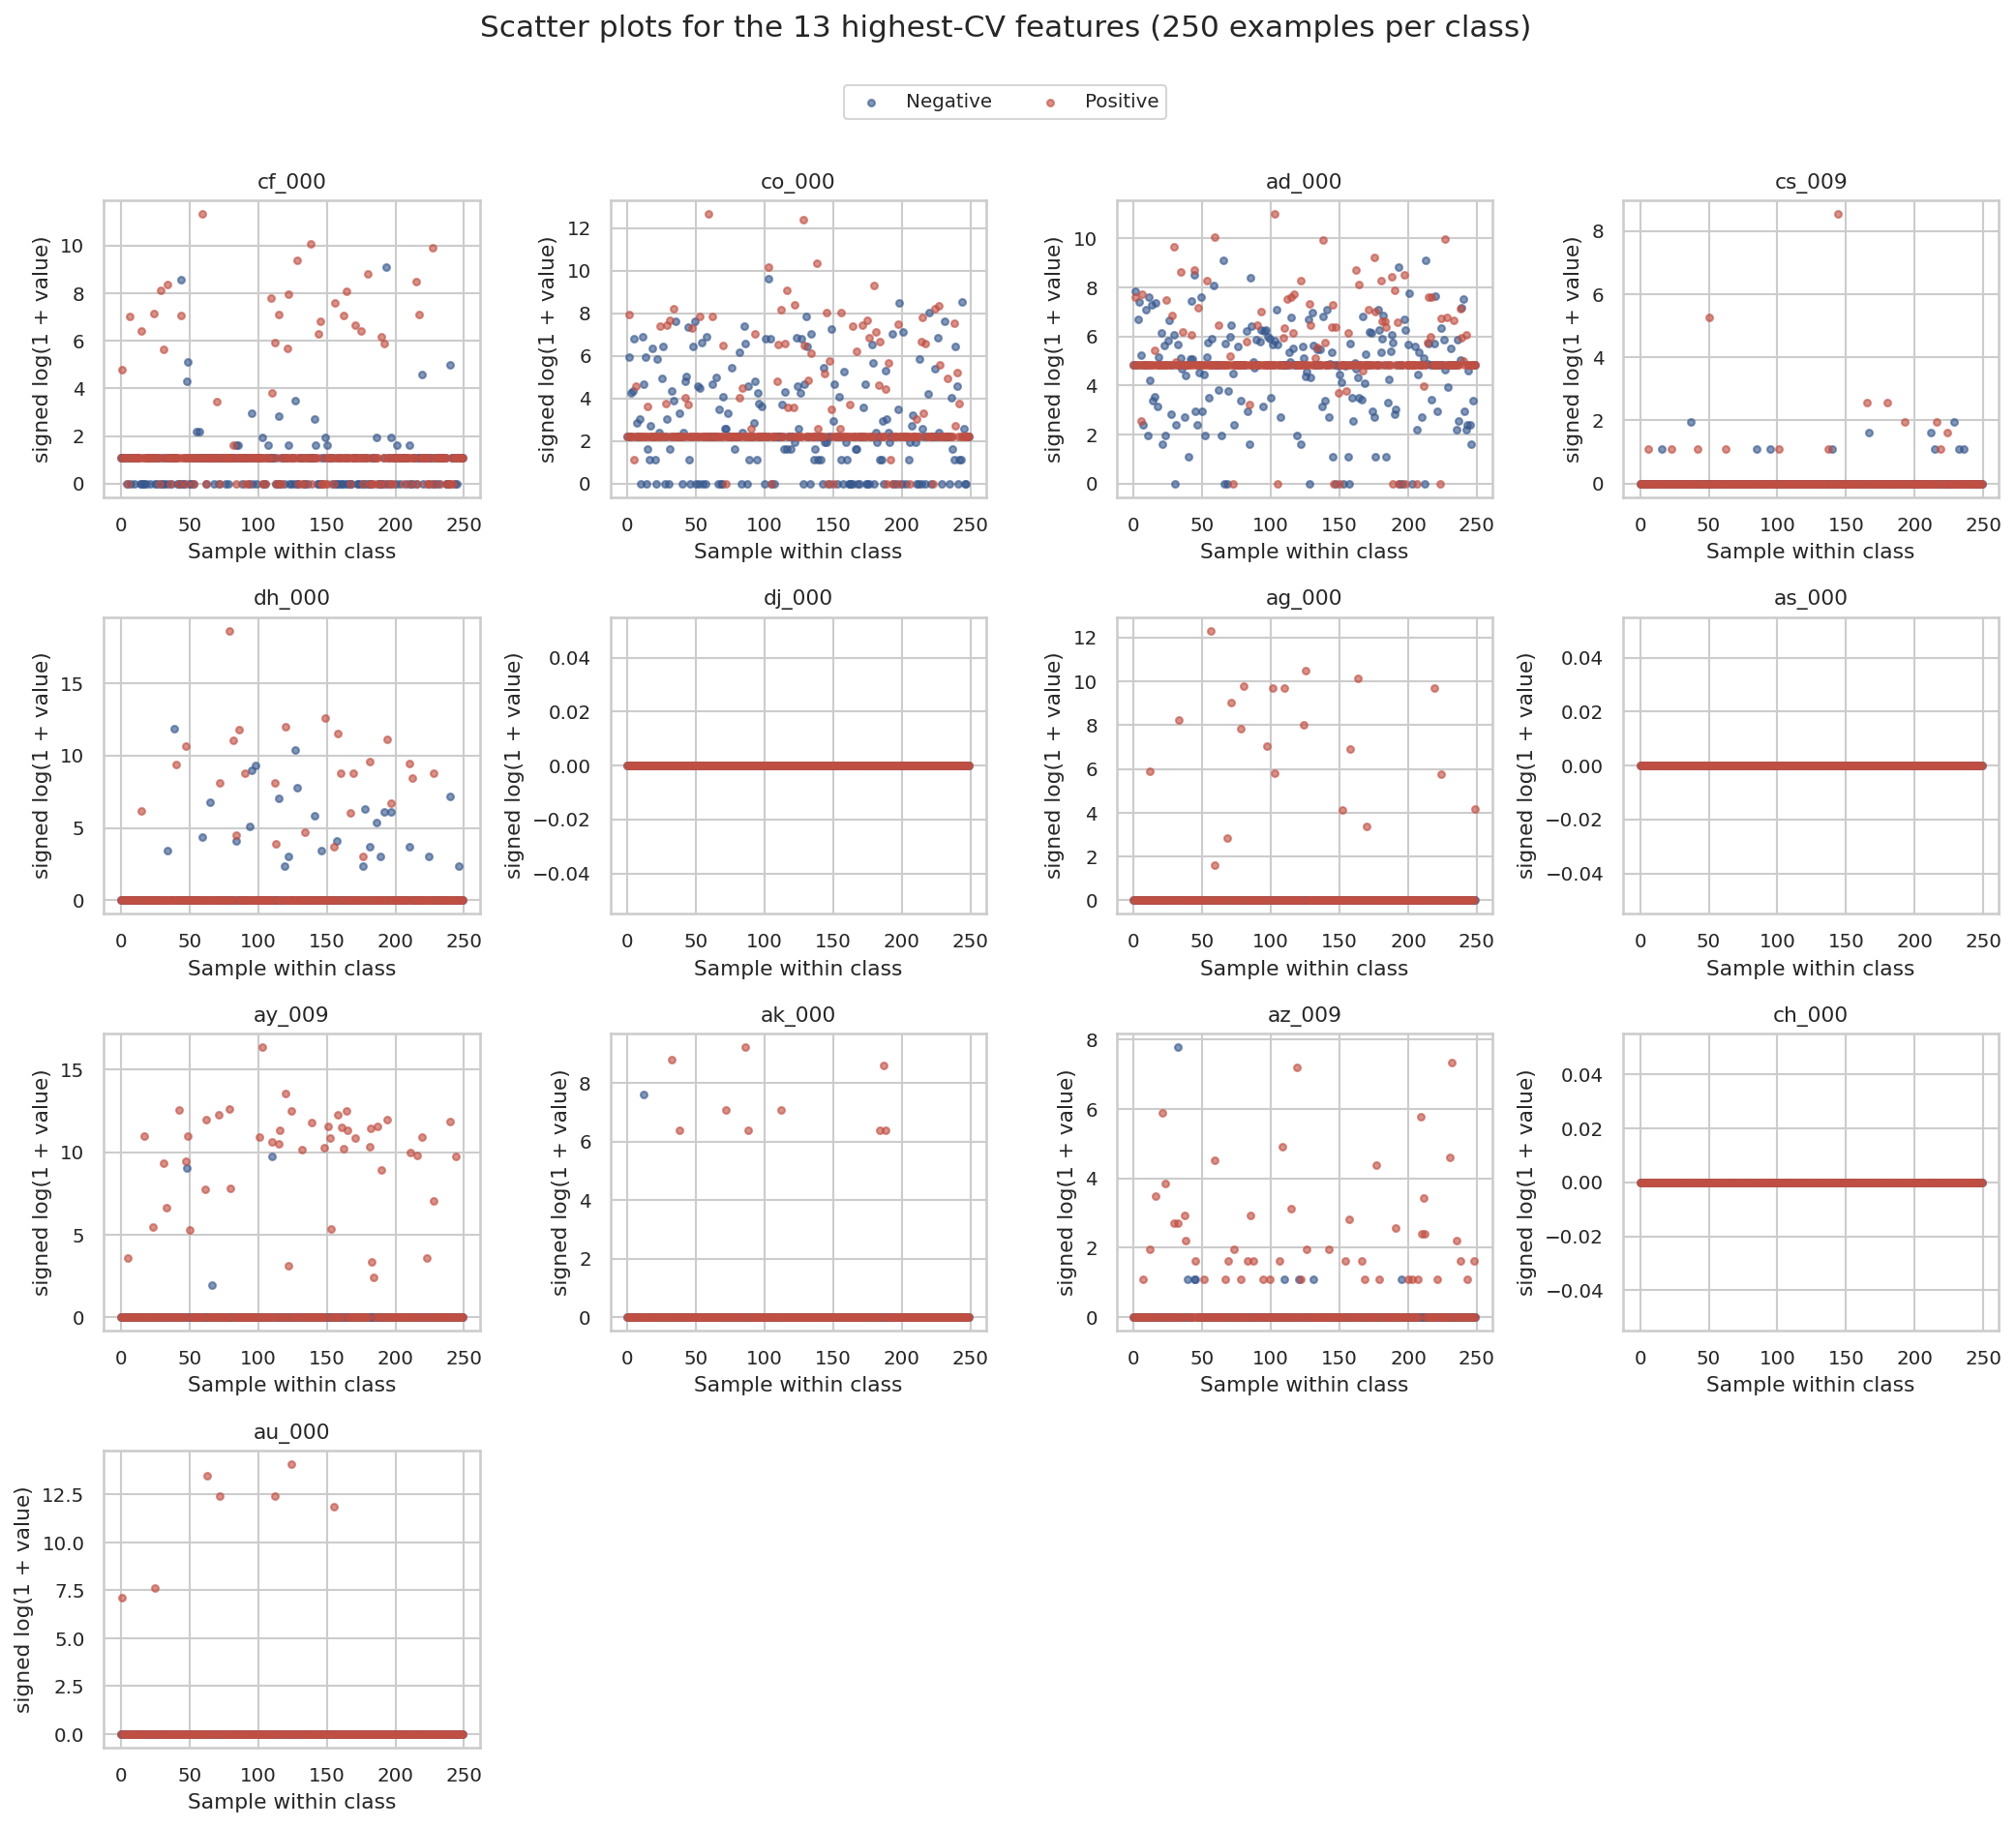

04_boxplots_top_13_by_class.png


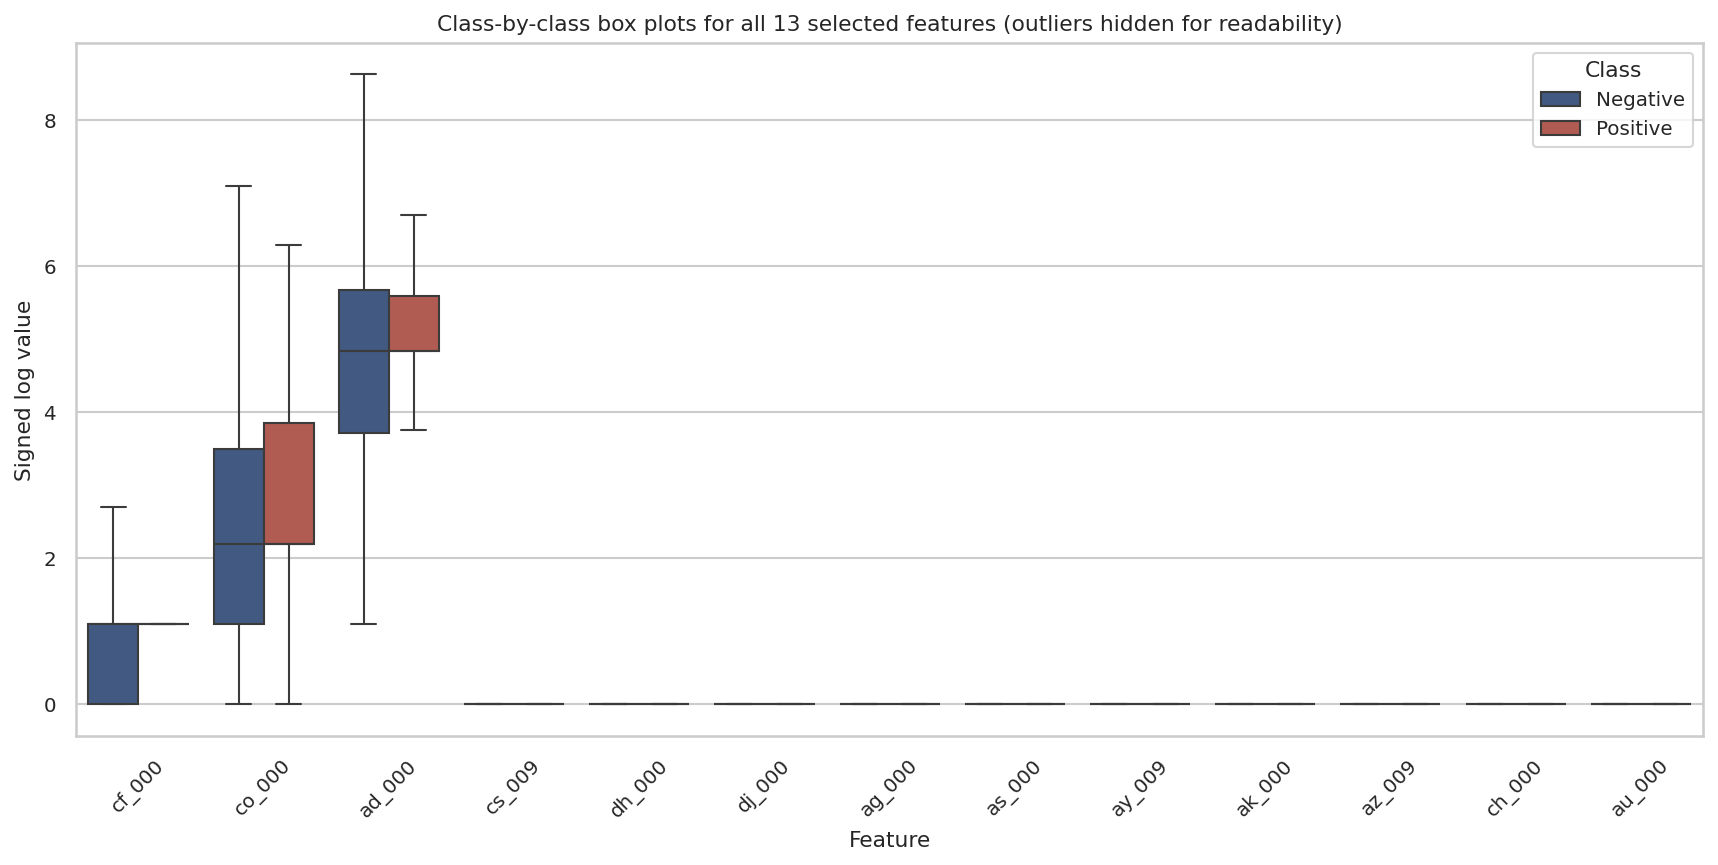

05_pairwise_scatter.png


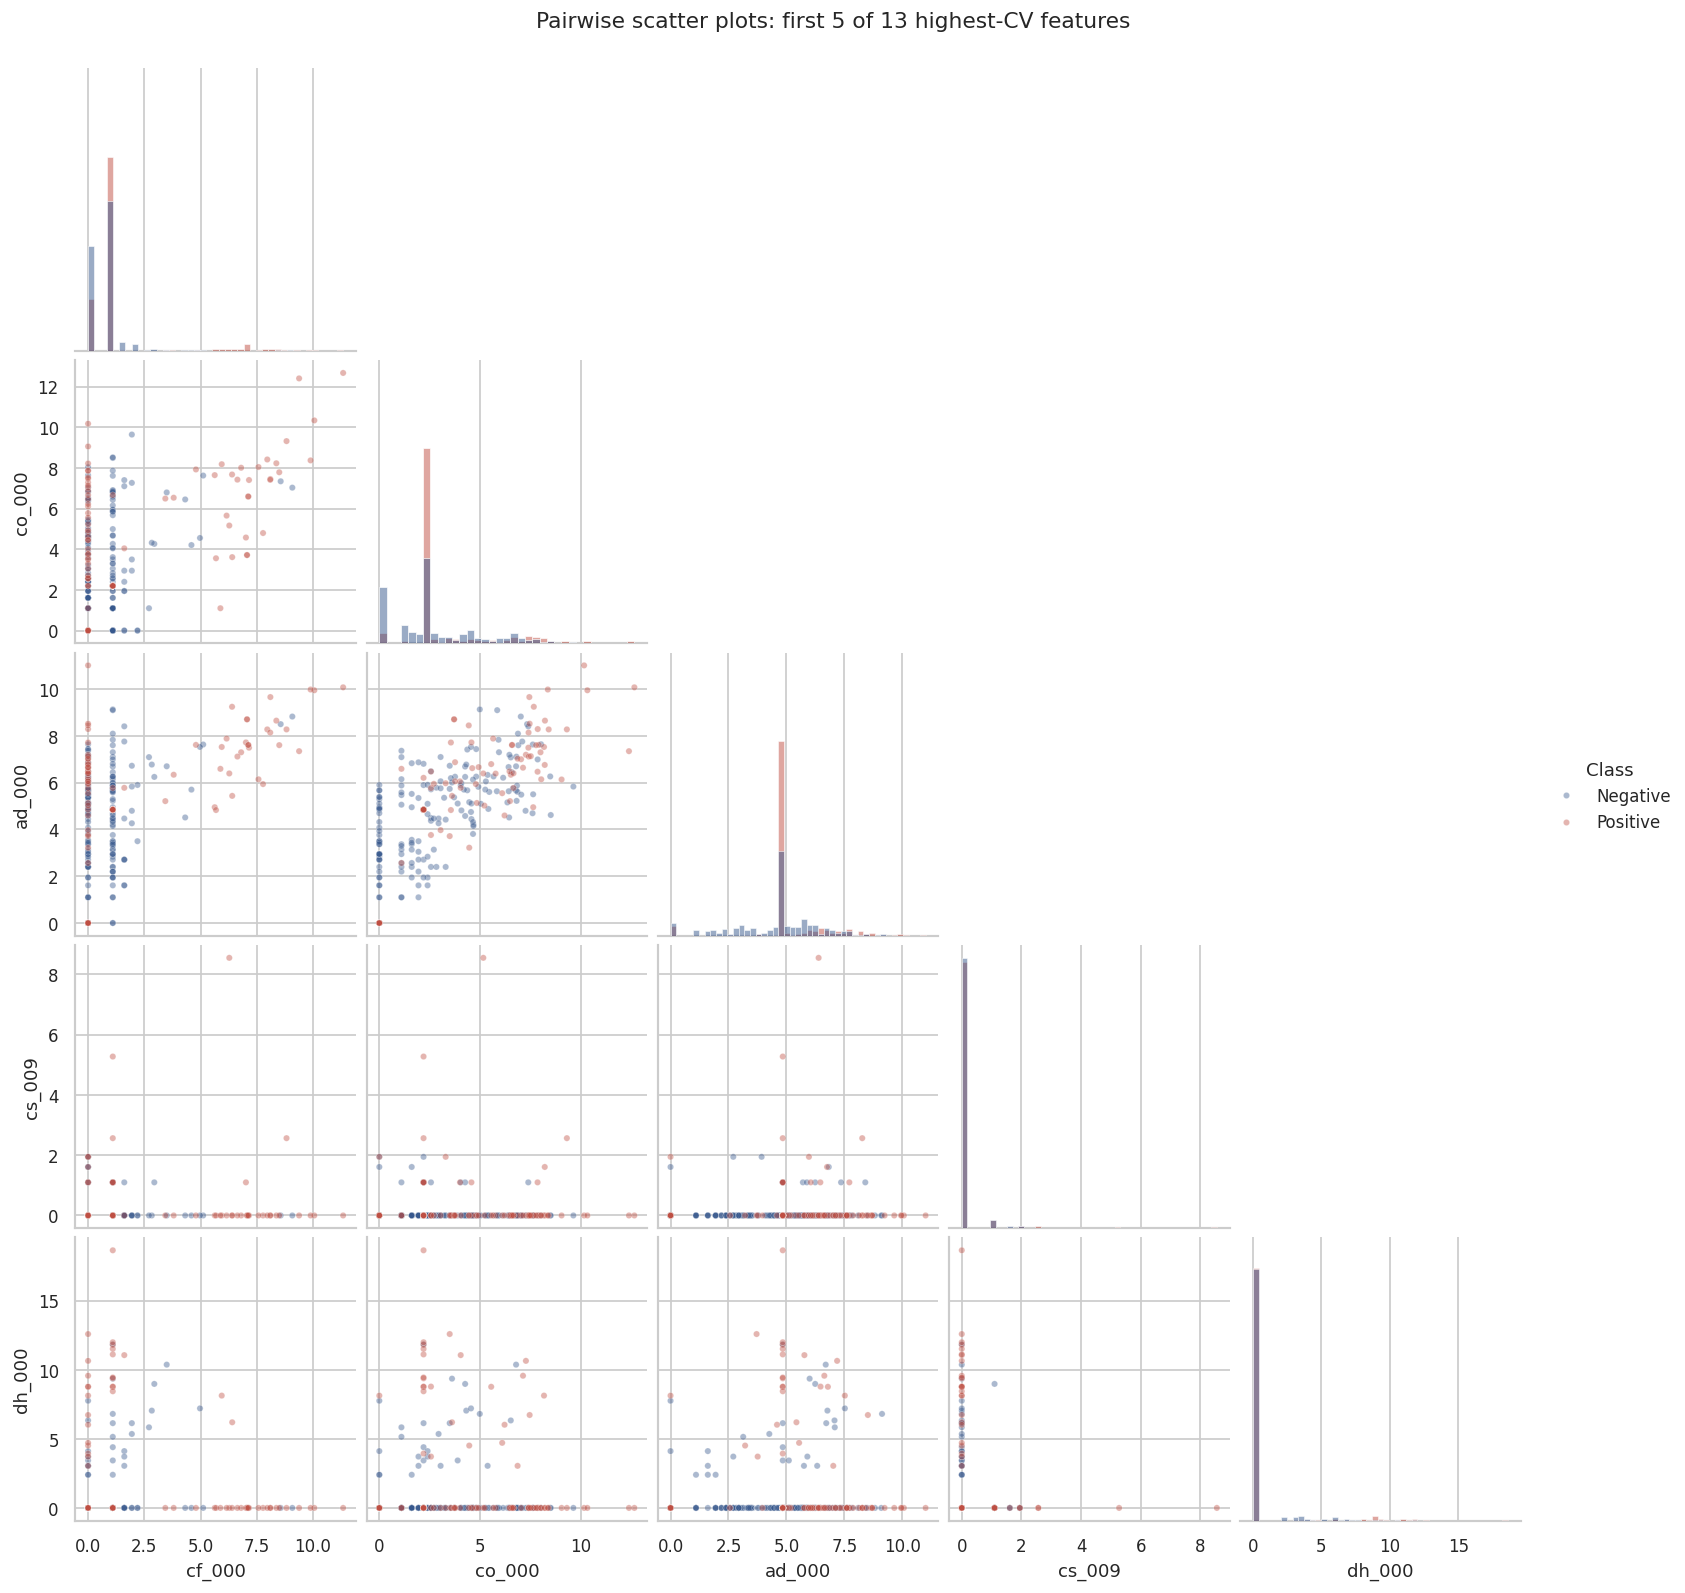

In [3]:
for name in ['02_top_13_cv.png','01_correlation_all_features.png','03_scatter_top_13_by_class.png','04_boxplots_top_13_by_class.png','05_pairwise_scatter.png']:
 print(name)
 display(Image(filename=str(ROOT/'figures'/name),width=650))

### Is the dataset imbalanced?
Yes. The training set has **59,000 negative cases** and **1,000 positive cases**: 98.33% versus 1.67%. Predicting negative all the time would look accurate but would miss every failure.

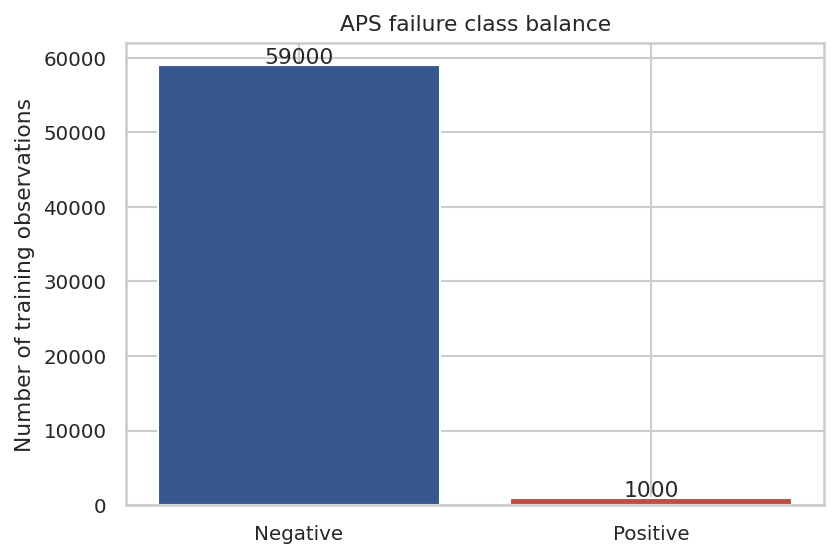

In [4]:
display(Image(filename=str(ROOT/'figures/06_class_balance.png'),width=550))

## 1(c) and 1(d) Random forests
The first forest has no class balancing. The second uses balanced class weights within each tree. Both were fitted on the original training data and evaluated on the original test data. OOB error comes from training rows left out when individual trees were fitted.

In [5]:
for k,name in [('random_forest','Unweighted forest'),('weighted_random_forest','Weighted forest')]:
 a=result['models'][k]
 print('\n',name,'OOB error:',f"{a['oob_error']:.4%}",'test error:',f"{a['test']['error']:.4%}")
 display(pd.DataFrame([{'Split':s,**a[s]} for s in ['train','test']]).set_index('Split')[['tn','fp','fn','tp','error','auc']])


 Unweighted forest OOB error: 0.5817% test error: 0.7437%


,tn,fp,fn,tp,error,auc
Split,,,,,,
train,59000,0,0,1000,0.000000,1.00000
test,15608,17,102,273,0.007437,0.99432



 Weighted forest OOB error: 0.7683% test error: 1.0688%


,tn,fp,fn,tp,error,auc
Split,,,,,,
train,59000,0,0,1000,0.000000,1.000000
test,15608,17,154,221,0.010688,0.993421


## 1(e) Corrected L1 logistic model tree (no SMOTE)
**Why this was redone:** A standard XGBoost tree does not train a logistic regression at its internal nodes. The corrected approach fits a separate **L1-penalized logistic regression** at each internal split, producing a weighted decision that can use several of the 170 features at once.

The tree uses training medians, a log-like transform, scaling, up to three levels, and an L1 penalty selected by five-fold validation AUC. The internal node code is in `l1_logistic_model_tree.py`; the training and validation code is in `cv_one_config.py` and `finalize_model_trees.py`.

In [6]:
from l1_logistic_model_tree import L1LogisticModelTree
assert L1LogisticModelTree(alpha=0.0003).max_depth==3
m=corrected['models']['l1_logistic_model_tree']
print('Chosen alpha:',m['alpha'],'Five-fold validation AUC:',round(m['cv_auc'],4),'test AUC:',round(m['test']['auc'],4))
display(pd.DataFrame([{'Split':s,**m[s]} for s in ['train','test']]).set_index('Split')[['tn','fp','fn','tp','error','auc','recall']])

Chosen alpha: 0.0003 Five-fold validation AUC: 0.9213 test AUC: 0.9266


,tn,fp,fn,tp,error,auc,recall
Split,,,,,,,
train,58947,53,418,582,0.007850,0.934292,0.582
test,15597,28,171,204,0.012438,0.926625,0.544


## 1(f) Corrected L1 logistic model tree with SMOTE
SMOTE is applied only to each fold’s training rows, **never** to its validation rows. For the final model, the full original training dataset is used, resulting in 59,000 positives and 59,000 negatives. The 16,000-row test set is untouched.

Five-fold cross-validation chooses the regularization penalty from the same candidate values as before.

In [7]:
folds=pd.read_csv(ROOT/'results/model_tree_cv_folds.csv')
summary=pd.read_csv(ROOT/'results/model_tree_cv_summary.csv')
assert len(folds)==30 and set(folds['fold'])=={1,2,3,4,5}
display(summary.round(5))
s=corrected['models']['l1_logistic_model_tree_smote']
print('SMOTE model chosen alpha:',s['alpha'],'Five-fold validation AUC:',round(s['cv_auc'],4),'test AUC:',round(s['test']['auc'],4))
display(pd.DataFrame([{'Split':x,**s[x]} for x in ['train','test']]).set_index('Split')[['tn','fp','fn','tp','error','auc','recall']])

,smote,alpha,mean_auc,sd_auc,mean_cv_error,mean_recall,mean_cost_per_fold
0,False,0.0001,0.91941,0.01825,0.00928,0.584,41882
1,False,0.0003,0.92131,0.02506,0.00907,0.615,38818
2,False,0.0010,0.91863,0.02791,0.00943,0.600,40332
3,True,0.0001,0.94705,0.00827,0.02730,0.866,16408
4,True,0.0003,0.95271,0.00946,0.03062,0.883,15140
5,True,0.0010,0.95754,0.00675,0.03255,0.909,12824


SMOTE model chosen alpha: 0.001 Five-fold validation AUC: 0.9575 test AUC: 0.9766


,tn,fp,fn,tp,error,auc,recall
Split,,,,,,,
train,57184,1816,17,983,0.030550,0.986715,0.983000
test,15166,459,23,352,0.030125,0.976574,0.938667


16_model_tree_alpha_cv.png


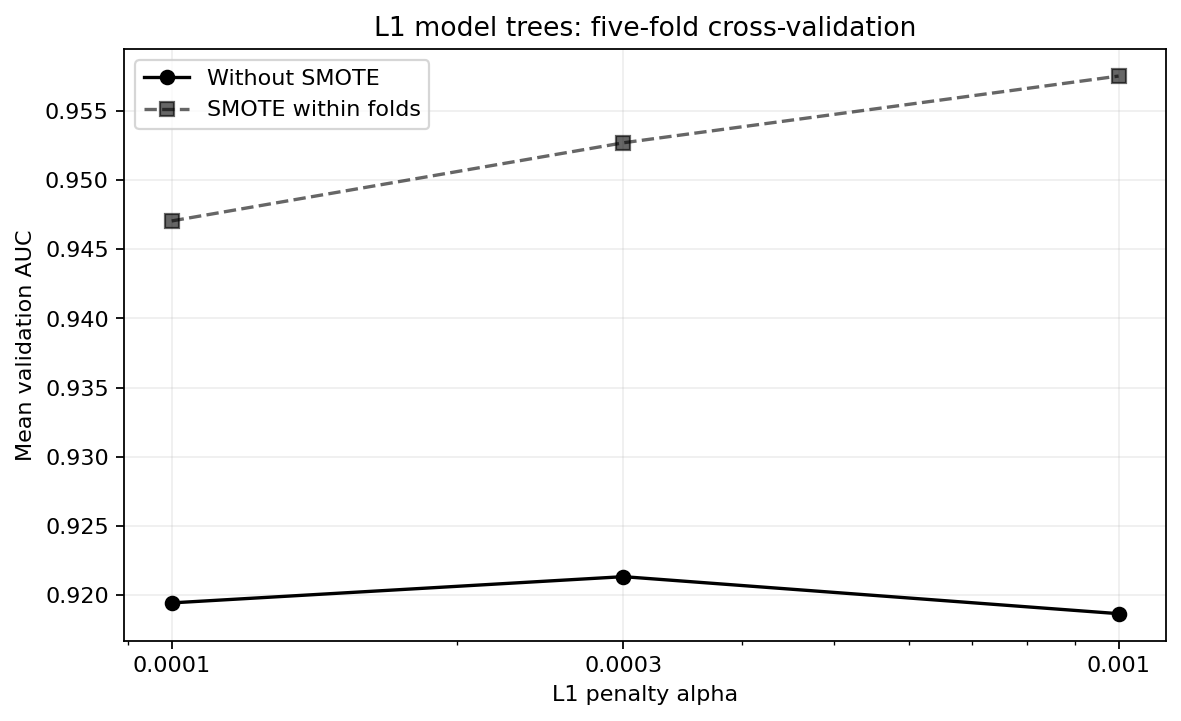

17_model_tree_roc.png


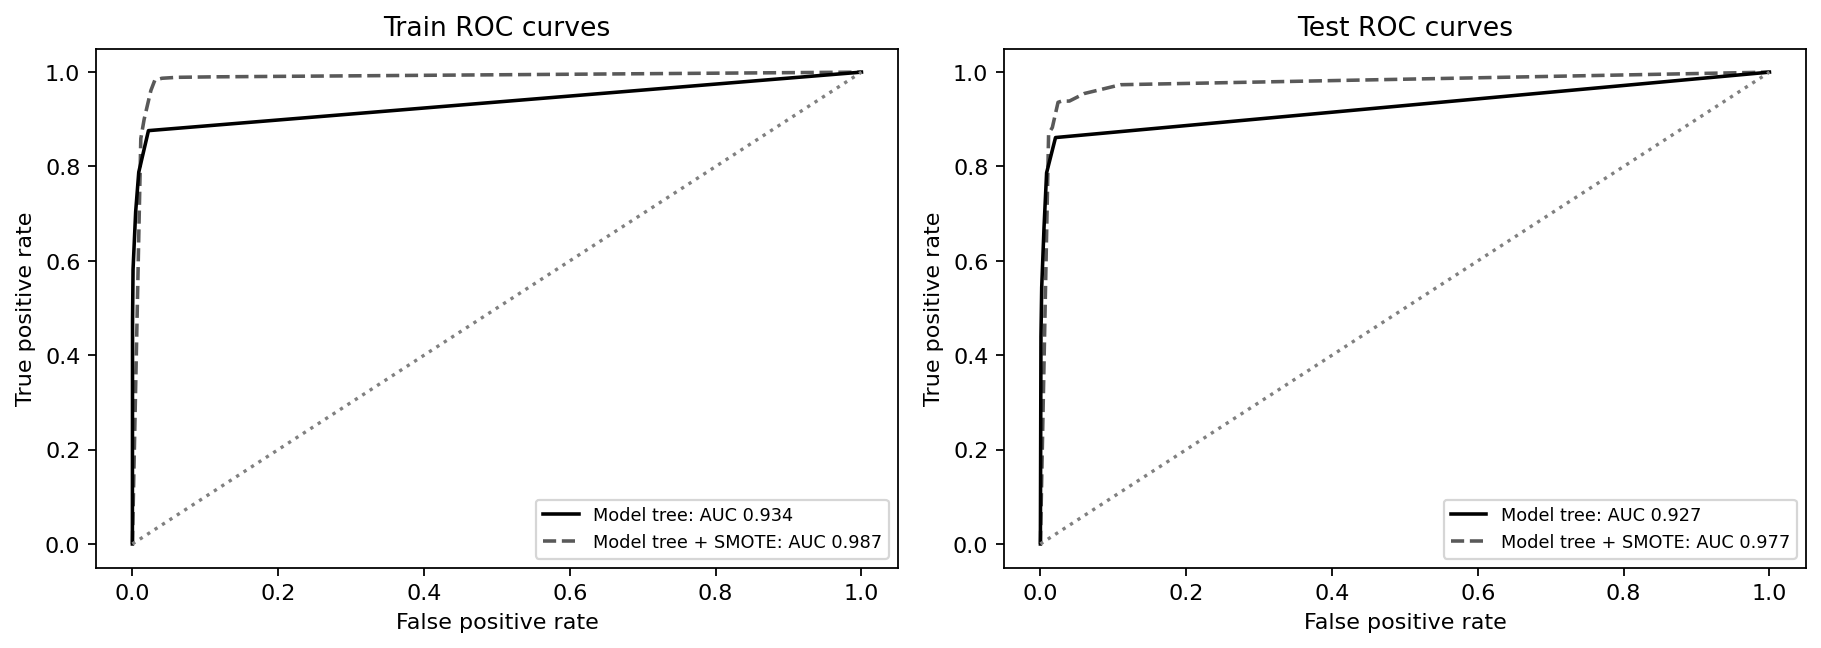

18_model_tree_confusion.png


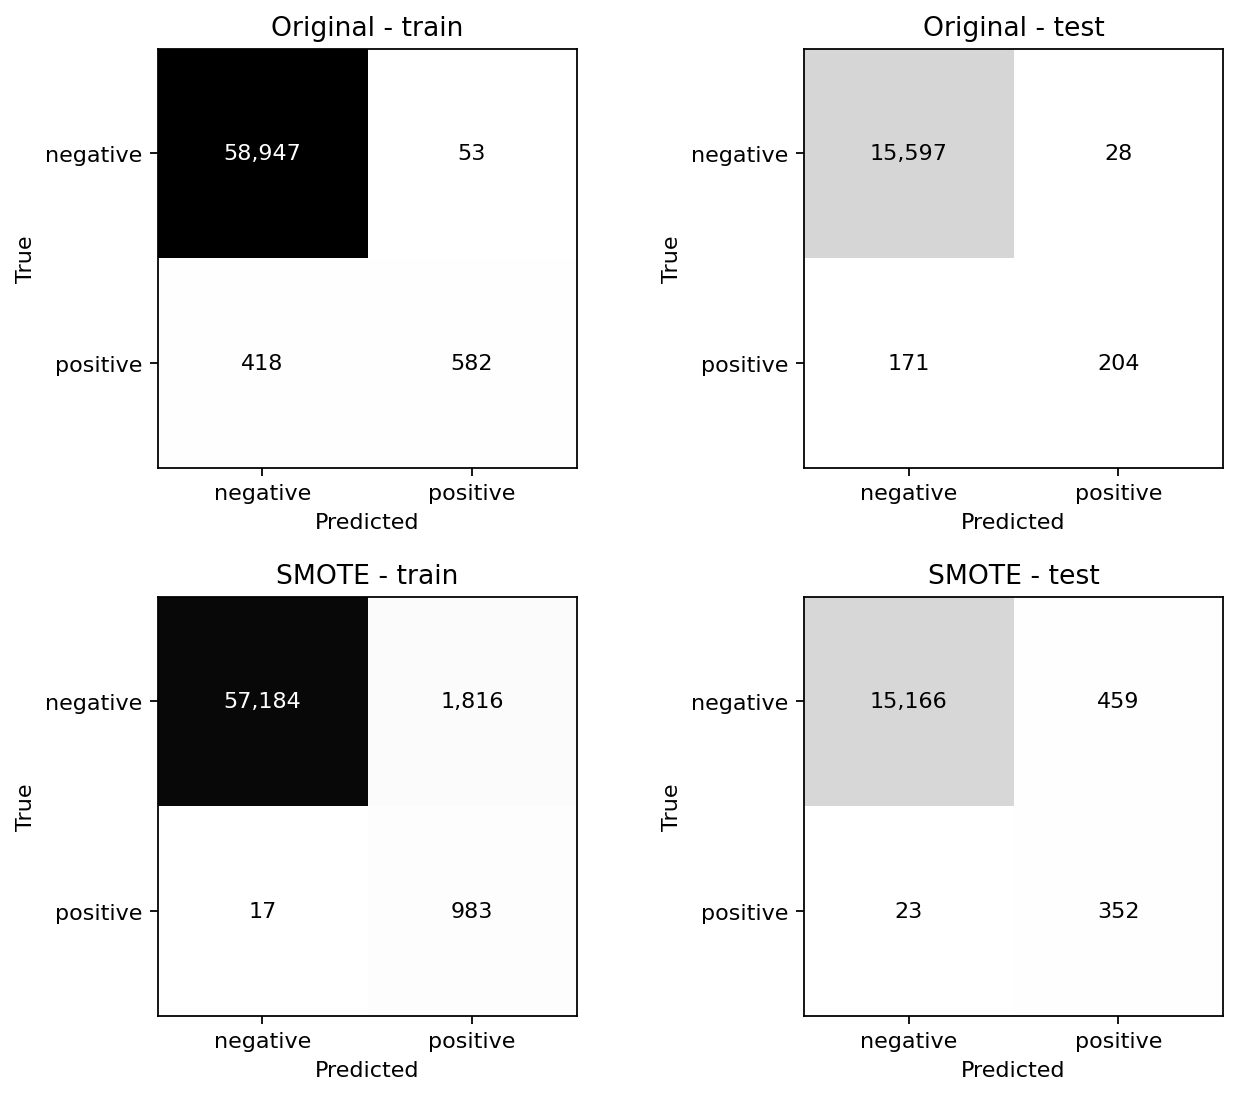

In [8]:
for name in ['16_model_tree_alpha_cv.png','17_model_tree_roc.png','18_model_tree_confusion.png']:
 print(name)
 display(Image(filename=str(ROOT/'figures'/name),width=650))

### What the corrected comparison means
The regular model tree catches **204 of 375 failures**, missing 171 and creating 28 false alarms. The SMOTE model catches **352 of 375**, missing 23, but it creates 459 false alarms. The improvement in failure detection comes with a rise in overall error.

## Additional comparison: conventional XGBoost
Because the assignment mentions XGBoost, the original standard XGBoost runs are retained below as a **separate comparison**. Their `reg_alpha` setting penalizes tree-leaf outputs; it does **not** create L1 logistic regressions at internal split nodes. The complete XGBoost training code is in `run_original_baselines.py`.

In [9]:
rows=[]
for key,label in [('random_forest','Random forest'),('weighted_random_forest','Weighted forest'),('xgboost','Conventional XGBoost'),('xgboost_smote','XGBoost + SMOTE')]:
 a=result['models'][key]['test'];rows.append({'Model':label,'Test AUC':a['auc'],'Test error':a['error'],'Missed failures':a['fn'],'False alarms':a['fp']})
for key,label in [('l1_logistic_model_tree','Corrected model tree'),('l1_logistic_model_tree_smote','Corrected model tree + SMOTE')]:
 a=corrected['models'][key]['test'];rows.append({'Model':label,'Test AUC':a['auc'],'Test error':a['error'],'Missed failures':a['fn'],'False alarms':a['fp']})
display(pd.DataFrame(rows).set_index('Model').round(5))

,Test AUC,Test error,Missed failures,False alarms
Model,,,,
Random forest,0.99432,0.00744,102,17
Weighted forest,0.99342,0.01069,154,17
Conventional XGBoost,0.99584,0.00700,98,14
XGBoost + SMOTE,0.99424,0.01631,36,225
Corrected model tree,0.92663,0.01244,171,28
Corrected model tree + SMOTE,0.97657,0.03012,23,459


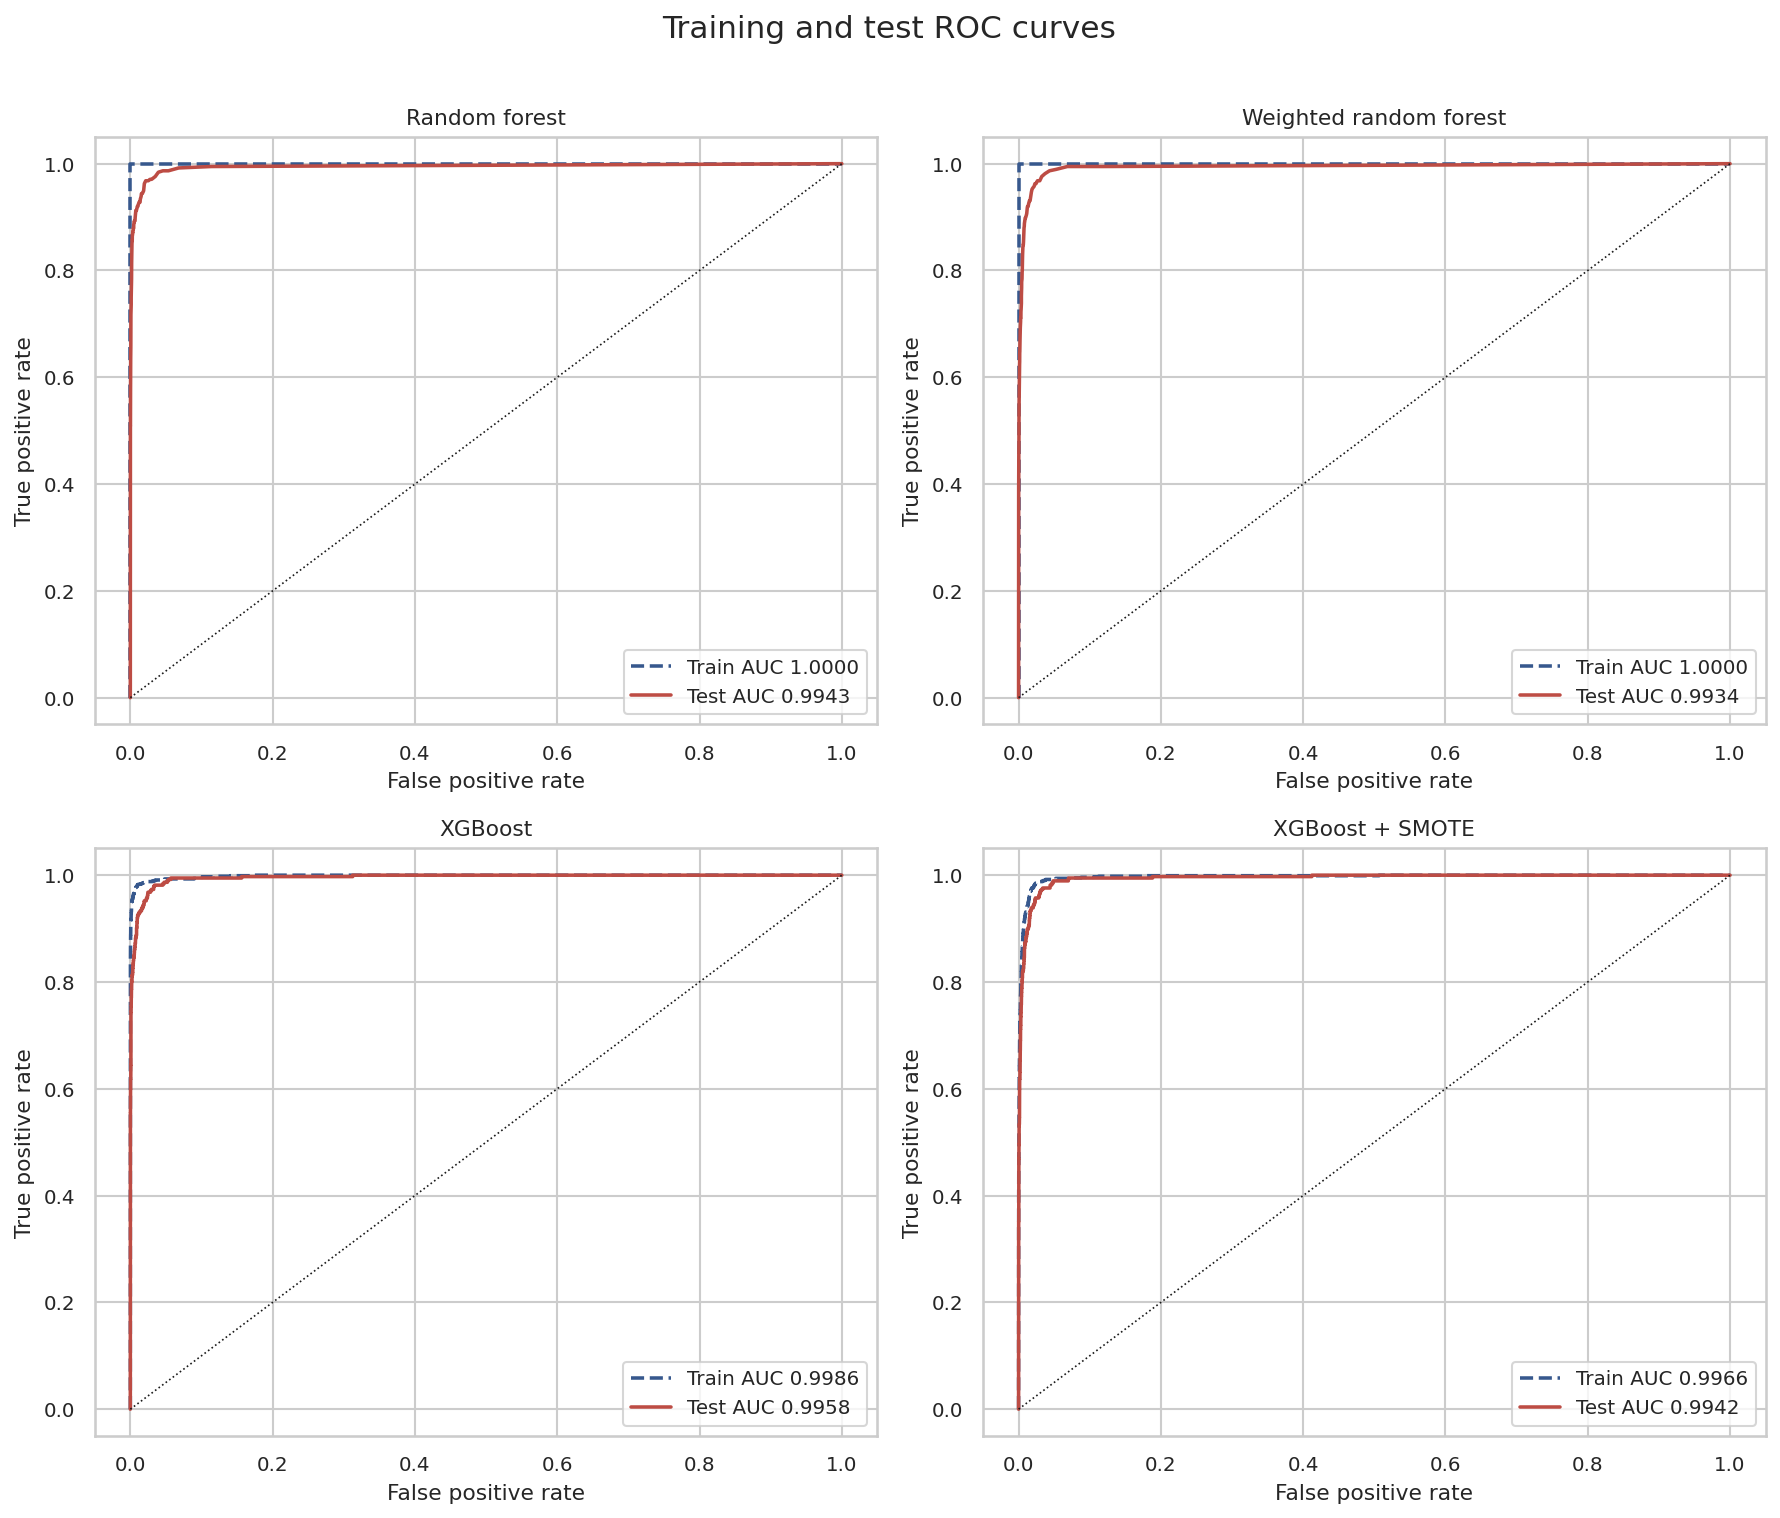

In [10]:
display(Image(filename=str(ROOT/'figures/07_roc_curves.png'),width=650))

## 2. ISLR 6.6.3: Increasing the lasso constraint

| Question | Answer | Reason |
|---|---|---|
| (a) Training RSS | **iv. Decreases** | More flexibility cannot hurt the best training fit. |
| (b) Test RSS | **ii. U-shaped** | It often improves and then overfits. |
| (c) Variance | **iii. Increases** | A flexible fit is more sensitive to the sample. |
| (d) Squared bias | **iv. Decreases** | The fit can reflect more of the true pattern. |
| (e) Irreducible error | **v. Constant** | Unpredictable noise does not change. |


## 3. ISLR 6.6.5: Ridge and lasso when predictors are identical

Let the two identical columns be $(a,-a)$, the responses be $(b,-b)$, and $t=\beta_1+\beta_2$. Predictions depend only on $t$.

**(a) Ridge:** minimize $2(b-at)^2+\lambda(\beta_1^2+\beta_2^2)$.

**(b) Ridge solution:** for a fixed sum $t$, the squared penalty is smallest when $\beta_1=\beta_2=t/2$. Therefore both equal $2ab/(4a^2+\lambda)$ when $\lambda>0$.

**(c) Lasso:** minimize $2(b-at)^2+\lambda(|\beta_1|+|\beta_2|)$.

**(d) Lasso is not necessarily unique:** for any nonzero optimal total $t$ and coefficients with the same sign, the pairs $(0,t)$, $(t/2,t/2)$, and $(t,0)$ give identical fit and penalty. The optimal total is $\mathrm{sign}(b/a)\max(|b/a|-\lambda/(4a^2),0)$ for $a\ne0$. If the optimum is zero and $\lambda>0$, the only solution is $(0,0)$.


## 4. ISLR 8.4.5: Majority vote versus averaging probabilities

Six of the ten trees predict Red with probability above 0.50, so **majority vote gives Red**. The red probabilities total 4.50, making their average 0.45, so **average probability gives Green**. The two methods differ because voting ignores confidence while averaging uses it.


## 5. ISLR 9.7.3: The separating line

**(a)** Red: (3,4), (2,2), (4,4), (1,4). Blue: (2,1), (4,3), (4,1).

**(b)** Best line: $X_2=X_1-0.5$. **(c)** Predict Red if $0.5-X_1+X_2>0$. Coefficients: $\beta_0=0.5,\beta_1=-1,\beta_2=1$.

**(d)** Margins: $X_2=X_1$ and $X_2=X_1-1$; distance to the center line on each side is $0.5/\sqrt 2$.

**(e)** Support vectors are Red points 2 and 3 and Blue points 5 and 6. **(f)** Small changes to point 7 do not change the line since it is not a support vector.

**(g)** $X_2=0.75X_1+0.30$ is another separator but has a smaller margin. **(h)** A new Red point at (3,2) lies on the segment between Blue points (2,1) and (4,3); a straight line can no longer separate the classes.


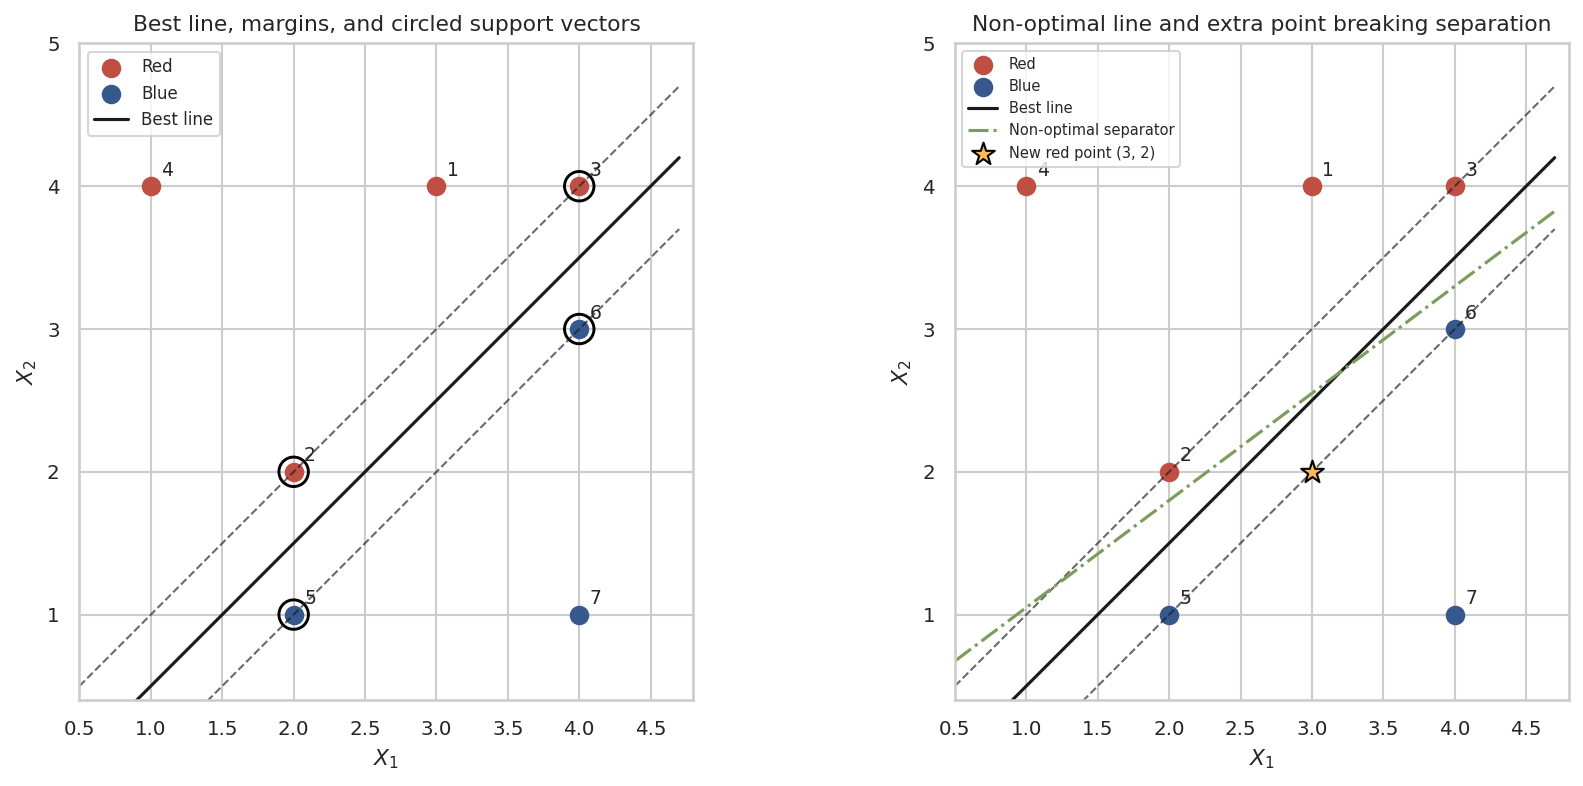

In [11]:
display(Image(filename=str(ROOT/'figures/11_islr_9_7_3_diagram.png'),width=700))

## 6. Extra practice (optional)

**ISLR 5.4.2:** Probability a row is included in a bootstrap sample of size $n$: $1-(1-1/n)^n$. For $n=5$, 0.67232; for $n=100$, 0.63397; for $n=10,000$, 0.63214. The limit is $1-e^{-1}$ or about 0.63212. A seeded simulation of 10,000 samples of size 100 included the selected row about 0.6304 of the time.

**ISLR 6.8.4 (first-edition numbering):** As ridge lambda grows: (a) Training RSS iii, increases; (b) Test RSS ii, U-shaped; (c) variance iv, decreases; (d) squared bias iii, increases; (e) irreducible error v, constant.

**ISLR 8.4.4:** (a) The rightmost region has value 5 for $X_1\ge1$. On the left, splits at $X_1=0$ and $X_2=1$ produce values 15, 3, 0, and 10. (b) Starting with $X_2=1$, the lower region splits at $X_1=1$ into -1.80 and 0.63. Between $X_2=1$ and $X_2=2$, a split at $X_1=0$ gives -1.06 and 0.21. Above $X_2=2$ the answer is 2.49.

**ISLR 9.7.2:** The curve $(1+X_1)^2+(2-X_2)^2=4$ is a circle centered at (-1,2) with radius 2. Outside means expression greater than 4; inside or on means at most 4. Points (0,0), (2,2), (3,8) are Blue; (-1,1) is Red. Expanding yields $1+2X_1+X_1^2-4X_2+X_2^2=0$, linear in the expanded features.


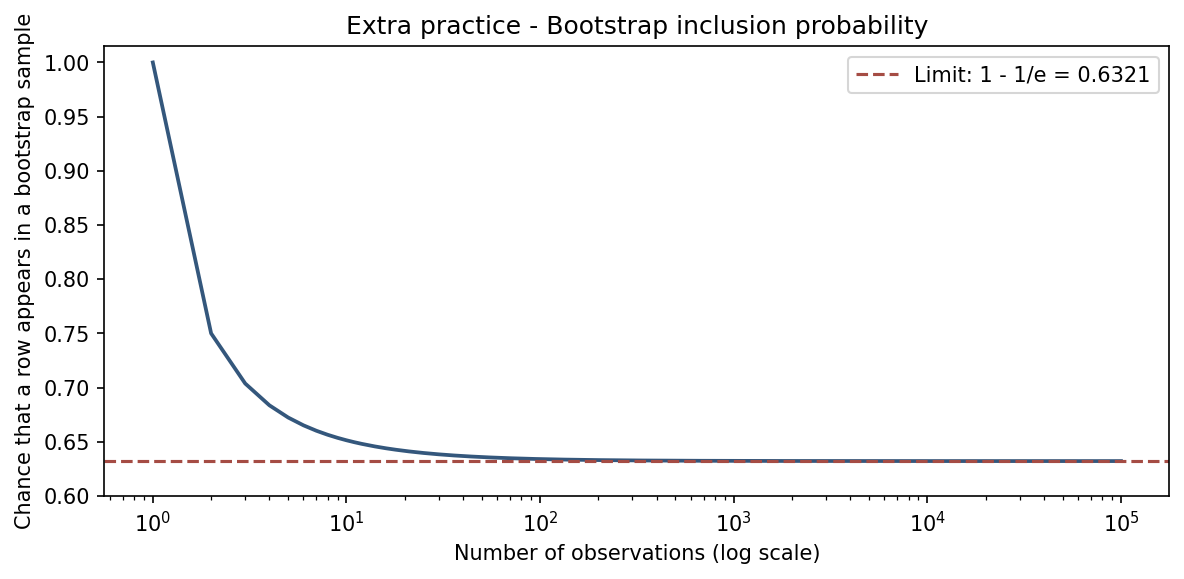

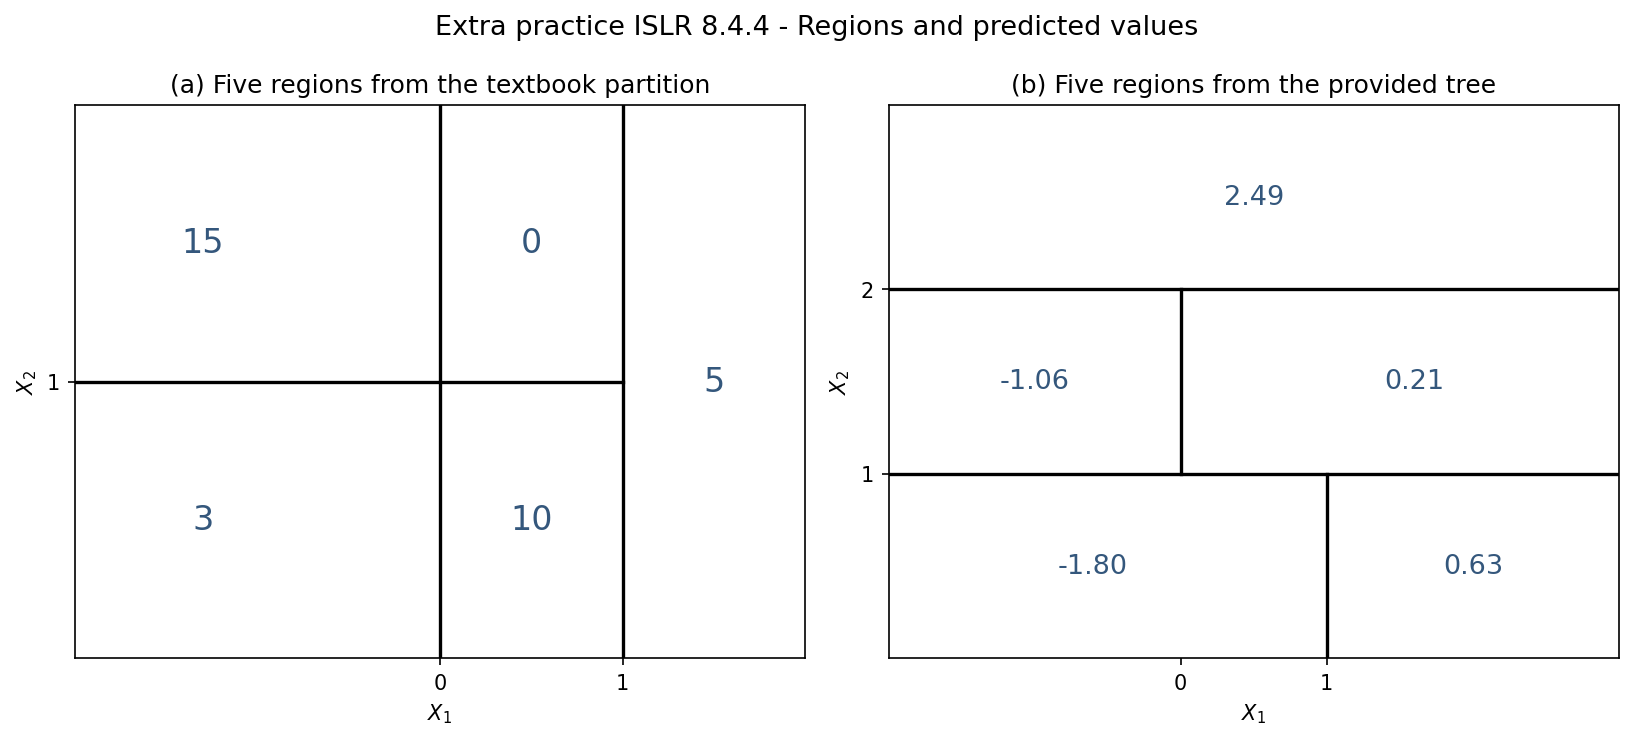

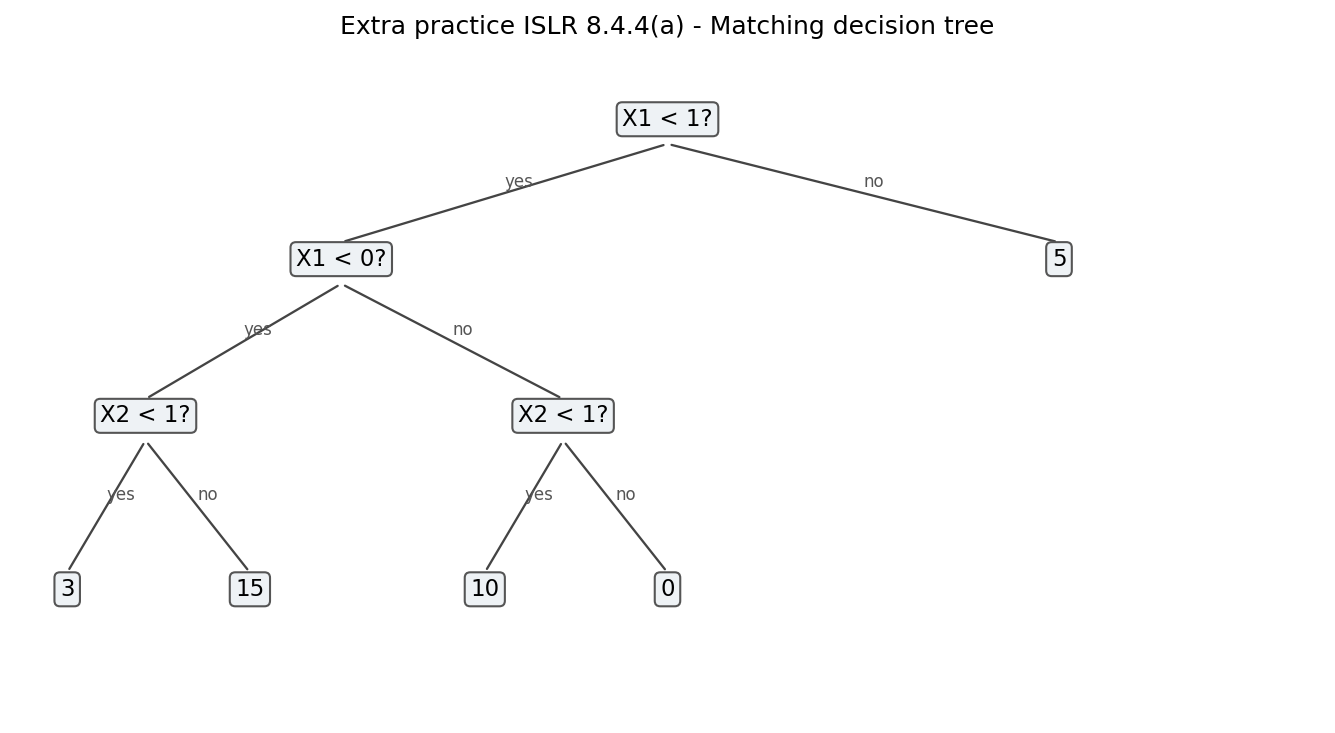

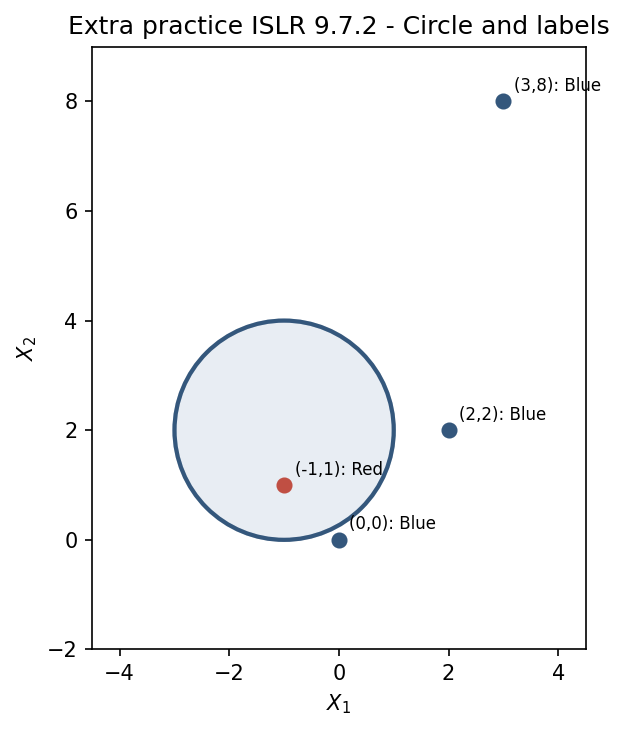

In [12]:
for name in ['12_bootstrap_probability.png','13_islr_8_4_4_partitions.png','15_islr_8_4_4_tree.png','14_islr_9_7_2_circle.png']:
 display(Image(filename=str(ROOT/'figures'/name),width=620))

## How to reproduce the model fitting

Every model and fold can be rerun using the included source files. From this folder, run `python run_all.py` in a terminal after installing `requirements.txt`. This runs the original forests and conventional XGBoost, the six L1 logistic model-tree validation configurations (five folds each), the final full-data SMOTE model, and the PDF generator. The notebook displays the saved, verified outputs so it remains quick to open.

## References and AI use acknowledgment

The sources are the supplied Homework 6 sheet and APS data, the UCI APS Failure dataset, *An Introduction to Statistical Learning*, scikit-learn, and the official XGBoost parameter documentation.

**AI use acknowledgment:** AI tools were used to assist with organizing the code, compiling the report, and checking formatting. All reported numerical results were generated from the included APS datasets using the accompanying reproducible code.